In [1]:
import pandas as pd
import numpy as np
import os

from catboost import CatBoostRegressor

BASE_DIR = r"C:\Users\vikra\Desktop\Supply Chain Algo"

DATA_DIR = os.path.join(BASE_DIR, "Data")
RAW_DIR = os.path.join(DATA_DIR, "Raw")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")

MODEL_DIR = os.path.join(BASE_DIR, "models")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

os.makedirs(REPORT_DIR, exist_ok=True)

# Load optimized CatBoost model
model_path = os.path.join(
    MODEL_DIR,
    "optimized_catboost_model.cbm"
)

model = CatBoostRegressor()
model.load_model(model_path)

print("Optimized CatBoost model loaded!")

Optimized CatBoost model loaded!


In [2]:
# Load datasets
history = pd.read_csv(
    os.path.join(PROCESSED_DIR, "sales_clean.csv")
)

future = pd.read_csv(
    os.path.join(RAW_DIR, "test.csv")
)

stores = pd.read_csv(
    os.path.join(PROCESSED_DIR, "stores_clean.csv")
)

holidays = pd.read_csv(
    os.path.join(RAW_DIR, "holidays_events.csv")
)

# Normalize column names
for data in [history, future, stores, holidays]:
    data.columns = data.columns.str.strip().str.lower()

# Convert date columns
history["date"] = pd.to_datetime(history["date"])
future["date"] = pd.to_datetime(future["date"])
holidays["date"] = pd.to_datetime(holidays["date"])

print("Historical data:", history.shape)
print("Future data:", future.shape)
print("Stores:", stores.shape)
print("Holidays:", holidays.shape)

print("\nFuture date range:")
print(future["date"].min(), "to", future["date"].max())

display(future.head())

Historical data: (3000888, 21)
Future data: (28512, 5)
Stores: (54, 5)
Holidays: (350, 6)

Future date range:
2017-08-16 00:00:00 to 2017-08-31 00:00:00


,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [3]:
required_columns = [
    "id",
    "date",
    "store_nbr",
    "family",
    "onpromotion"
]

missing = [
    col for col in required_columns
    if col not in future.columns
]

assert not missing, f"Missing test columns: {missing}"

print("Future dataset validation successful!")

Future dataset validation successful!


In [4]:
history = history[
    ["date", "store_nbr", "family", "sales"]
].copy()

history["sales"] = pd.to_numeric(
    history["sales"],
    errors="coerce"
)

history = history.dropna(
    subset=["date", "store_nbr", "family", "sales"]
)

history["store_nbr"] = history["store_nbr"].astype(int)
history["family"] = history["family"].astype(str)

history = history.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

# Validate unique records
duplicates = history.duplicated(
    ["date", "store_nbr", "family"]
).sum()

print("Historical duplicates:", duplicates)

assert duplicates == 0, "Resolve duplicate records before forecasting."

Historical duplicates: 0


In [5]:
history_sales = {}

for (store, family), group in history.groupby(
    ["store_nbr", "family"]
):
    history_sales[(int(store), str(family))] = (
        group.sort_values("date")["sales"].tolist()
    )

print("Historical store-category combinations:",
      len(history_sales))

Historical store-category combinations: 1782


In [6]:
# Clean store information
store_lookup = stores[
    ["store_nbr", "city", "state"]
].drop_duplicates().copy()

store_lookup["store_nbr"] = (
    store_lookup["store_nbr"].astype(int)
)

store_lookup["city_key"] = (
    store_lookup["city"].astype(str).str.strip().str.casefold()
)

store_lookup["state_key"] = (
    store_lookup["state"].astype(str).str.strip().str.casefold()
)

# Clean holiday information
holiday_data = holidays.copy()

holiday_data["locale"] = (
    holiday_data["locale"]
    .astype(str)
    .str.strip()
    .str.casefold()
)

holiday_data["locale_name"] = (
    holiday_data["locale_name"]
    .astype(str)
    .str.strip()
    .str.casefold()
)

# Exclude events explicitly marked as transferred
if "transferred" in holiday_data.columns:
    transferred = (
        holiday_data["transferred"]
        .astype(str)
        .str.strip()
        .str.casefold()
        .isin(["true", "1", "yes"])
    )

    holiday_data = holiday_data[~transferred].copy()

In [7]:
holiday_records = []

for _, event in holiday_data.iterrows():

    event_date = event["date"]
    locale = event["locale"]
    locale_name = event["locale_name"]

    if locale == "national":

        matched_stores = store_lookup

    elif locale == "regional":

        matched_stores = store_lookup[
            store_lookup["state_key"] == locale_name
        ]

    elif locale == "local":

        matched_stores = store_lookup[
            store_lookup["city_key"] == locale_name
        ]

    else:
        continue

    for store_number in matched_stores["store_nbr"]:
        holiday_records.append({
            "date": event_date,
            "store_nbr": store_number
        })

holiday_store = pd.DataFrame(holiday_records)

if not holiday_store.empty:

    holiday_store = (
        holiday_store
        .groupby(["date", "store_nbr"])
        .size()
        .reset_index(name="holiday_event_count")
    )

    holiday_store["has_holiday_event"] = 1

else:

    holiday_store = pd.DataFrame(
        columns=[
            "date",
            "store_nbr",
            "holiday_event_count",
            "has_holiday_event"
        ]
    )

print("Holiday mapping created!")
display(holiday_store.head())

Holiday mapping created!


,date,store_nbr,holiday_event_count,has_holiday_event
0,2012-03-02,52,1,1
1,2012-03-02,53,1,1
2,2012-04-01,12,1,1
3,2012-04-01,13,1,1
4,2012-04-12,37,1,1


In [8]:
future = future.merge(
    holiday_store,
    on=["date", "store_nbr"],
    how="left",
    validate="many_to_one"
)

future["holiday_event_count"] = (
    future["holiday_event_count"].fillna(0)
)

future["has_holiday_event"] = (
    future["has_holiday_event"].fillna(0)
)

print("Future holiday features added!")

Future holiday features added!


In [9]:
future["year"] = future["date"].dt.year
future["month"] = future["date"].dt.month
future["day"] = future["date"].dt.day

future["day_of_week"] = (
    future["date"].dt.dayofweek
)

future["day_of_year"] = (
    future["date"].dt.dayofyear
)

future["week_of_year"] = (
    future["date"].dt.isocalendar().week.astype(int)
)

future["quarter"] = future["date"].dt.quarter

future["is_weekend"] = (
    future["day_of_week"] >= 5
).astype(int)

future["month_sin"] = np.sin(
    2 * np.pi * future["month"] / 12
)

future["month_cos"] = np.cos(
    2 * np.pi * future["month"] / 12
)

future["day_sin"] = np.sin(
    2 * np.pi * future["day_of_week"] / 7
)

future["day_cos"] = np.cos(
    2 * np.pi * future["day_of_week"] / 7
)

future["onpromotion"] = pd.to_numeric(
    future["onpromotion"],
    errors="coerce"
).fillna(0)

print("Future calendar features created!")

Future calendar features created!


In [10]:
categorical_features = [
    "store_nbr",
    "family"
]

numeric_features = [
    "onpromotion",
    "has_holiday_event",
    "holiday_event_count",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "quarter",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

feature_columns = (
    categorical_features + numeric_features
)

print("Features:", len(feature_columns))

Features: 24


In [11]:
model_features = model.feature_names_

if model_features:
    assert model_features == feature_columns, (
        "Model feature names or order do not match!"
    )

print("Model feature configuration verified!")

Model feature configuration verified!


### Build the recursive forecasting function

In [12]:
def get_lag_features(values):

    if len(values) < 28:
        raise ValueError(
            "Insufficient historical sales: "
            "at least 28 observations are required."
        )

    return {
        "sales_lag_1": values[-1],
        "sales_lag_7": values[-7],
        "sales_lag_14": values[-14],
        "sales_lag_28": values[-28],

        "sales_rolling_mean_7": np.mean(values[-7:]),
        "sales_rolling_mean_14": np.mean(values[-14:]),
        "sales_rolling_mean_28": np.mean(values[-28:])
    }

In [13]:
def recursive_forecasting(
    model,
    future_data,
    history_sales
):

    history_dict = {
        key: values.copy()
        for key, values in history_sales.items()
    }

    forecast_results = []

    future_data = future_data.sort_values(
        ["date", "store_nbr", "family"]
    ).copy()

    for forecast_date in sorted(
        future_data["date"].unique()
    ):

        daily_data = future_data[
            future_data["date"] == forecast_date
        ].copy()

        lag_features = []

        # Generate historical features
        for _, row in daily_data.iterrows():

            key = (
                int(row["store_nbr"]),
                str(row["family"])
            )

            values = history_dict.get(key, [])

            lag_features.append(
                get_lag_features(values)
            )

        lag_df = pd.DataFrame(
            lag_features,
            index=daily_data.index
        )

        daily_data = pd.concat(
            [daily_data, lag_df],
            axis=1
        )

        # Prepare model input
        X_day = daily_data[feature_columns].copy()

        for col in categorical_features:
            X_day[col] = X_day[col].astype(str)

        # Predict log-transformed demand
        predictions_log = model.predict(X_day)

        predictions = np.maximum(
            np.expm1(predictions_log),
            0
        )

        daily_data["predicted_sales"] = predictions

        # Update historical sales using predictions
        for _, row in daily_data.iterrows():

            key = (
                int(row["store_nbr"]),
                str(row["family"])
            )

            history_dict.setdefault(key, []).append(
                float(row["predicted_sales"])
            )

        forecast_results.append(
            daily_data[
                [
                    "id",
                    "date",
                    "store_nbr",
                    "family",
                    "onpromotion",
                    "predicted_sales"
                ]
            ].copy()
        )

        print(
            f"Forecast generated for {pd.Timestamp(forecast_date).date()}"
        )

    return pd.concat(
        forecast_results,
        ignore_index=True
    )

In [14]:
forecast_df = recursive_forecasting(
    model=model,
    future_data=future,
    history_sales=history_sales
)

print("Forecasting completed!")

print("Forecast Shape:", forecast_df.shape)

display(forecast_df.head(10))

Forecast generated for 2017-08-16
Forecast generated for 2017-08-17
Forecast generated for 2017-08-18
Forecast generated for 2017-08-19
Forecast generated for 2017-08-20
Forecast generated for 2017-08-21
Forecast generated for 2017-08-22
Forecast generated for 2017-08-23
Forecast generated for 2017-08-24
Forecast generated for 2017-08-25
Forecast generated for 2017-08-26
Forecast generated for 2017-08-27
Forecast generated for 2017-08-28
Forecast generated for 2017-08-29
Forecast generated for 2017-08-30
Forecast generated for 2017-08-31
Forecasting completed!
Forecast Shape: (28512, 6)


,id,date,store_nbr,family,onpromotion,predicted_sales
0,3000888,2017-08-16,1,AUTOMOTIVE,0,3.971071
1,3000889,2017-08-16,1,BABY CARE,0,0.030084
2,3000890,2017-08-16,1,BEAUTY,2,4.548280
3,3000891,2017-08-16,1,BEVERAGES,20,2014.342667
4,3000892,2017-08-16,1,BOOKS,0,0.038141
5,3000893,2017-08-16,1,BREAD/BAKERY,12,356.215070
6,3000894,2017-08-16,1,CELEBRATION,0,10.101365
7,3000895,2017-08-16,1,CLEANING,25,674.208420
8,3000896,2017-08-16,1,DAIRY,45,712.599655
9,3000897,2017-08-16,1,DELI,18,138.823811


In [15]:
print("Total forecast records:", len(forecast_df))

print("Forecast days:", forecast_df["date"].nunique())

print("Missing predictions:",
      forecast_df["predicted_sales"].isnull().sum())

print("Negative predictions:",
      (forecast_df["predicted_sales"] < 0).sum())

assert len(forecast_df) == len(future)
assert forecast_df["predicted_sales"].notna().all()

print("Forecast validation passed!")

Total forecast records: 28512
Forecast days: 16
Missing predictions: 0
Negative predictions: 0
Forecast validation passed!


In [16]:
daily_forecast = (
    forecast_df
    .groupby("date")["predicted_sales"]
    .sum()
    .reset_index()
)

daily_forecast.columns = [
    "date",
    "total_predicted_demand"
]

display(daily_forecast)

,date,total_predicted_demand
0,2017-08-16,777132.596585
1,2017-08-17,639619.190751
2,2017-08-18,735518.963563
3,2017-08-19,889540.308669
4,2017-08-20,983599.847618
5,2017-08-21,741047.652184
6,2017-08-22,692895.176759
7,2017-08-23,722286.006639
8,2017-08-24,616888.483619
9,2017-08-25,712609.835948


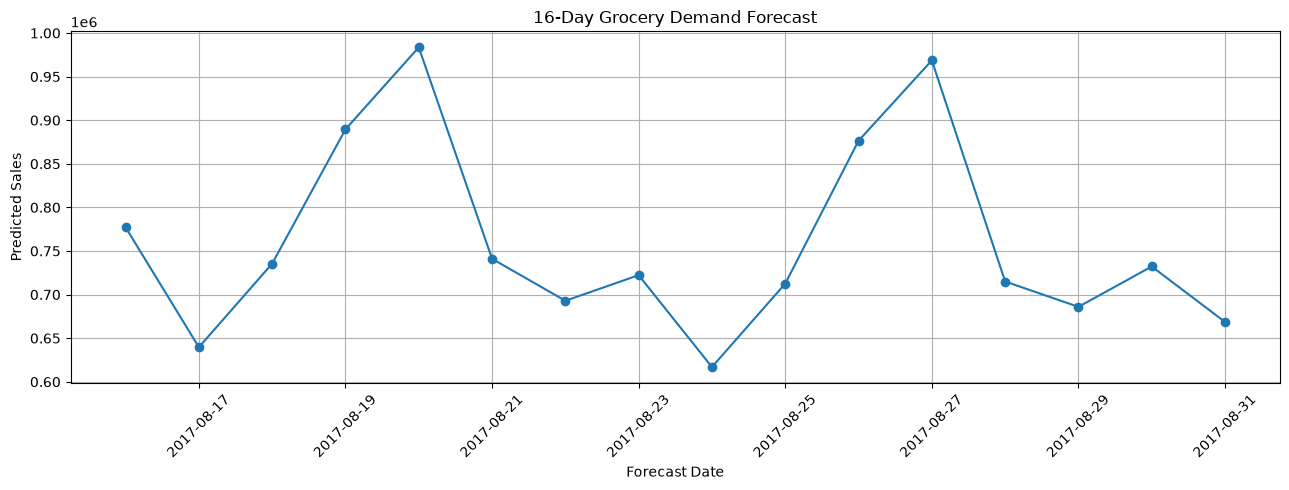

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(
    daily_forecast["date"],
    daily_forecast["total_predicted_demand"],
    marker="o"
)

plt.title("16-Day Grocery Demand Forecast")
plt.xlabel("Forecast Date")
plt.ylabel("Predicted Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
store_forecast = (
    forecast_df
    .groupby("store_nbr")["predicted_sales"]
    .sum()
    .reset_index()
    .sort_values(
        "predicted_sales",
        ascending=False
    )
)

store_forecast.columns = [
    "store_nbr",
    "total_predicted_demand"
]

display(store_forecast.head(20))

,store_nbr,total_predicted_demand
43,44,618624.128604
44,45,585462.200637
46,47,556242.913604
2,3,525156.196212
48,49,497868.415928
45,46,424036.616748
50,51,349886.855333
47,48,346106.762904
49,50,319807.371957
51,52,312927.297474


In [19]:
category_forecast = (
    forecast_df
    .groupby("family")["predicted_sales"]
    .sum()
    .reset_index()
    .sort_values(
        "predicted_sales",
        ascending=False
    )
)

category_forecast.columns = [
    "product_category",
    "total_predicted_demand"
]

display(category_forecast.head(20))

,product_category,total_predicted_demand
12,GROCERY I,3.646156e+06
3,BEVERAGES,2.698927e+06
30,PRODUCE,1.923016e+06
7,CLEANING,9.023655e+05
8,DAIRY,6.739821e+05
5,BREAD/BAKERY,4.272815e+05
28,POULTRY,2.881438e+05
24,MEATS,2.848660e+05
25,PERSONAL CARE,2.436885e+05
9,DELI,2.433903e+05


In [20]:
# Full prediction dataset
forecast_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "16_day_demand_forecast.csv"
    ),
    index=False
)

# Daily demand
daily_forecast.to_csv(
    os.path.join(
        REPORT_DIR,
        "daily_forecast_summary.csv"
    ),
    index=False
)

# Store demand
store_forecast.to_csv(
    os.path.join(
        REPORT_DIR,
        "store_demand_forecast.csv"
    ),
    index=False
)

# Product category demand
category_forecast.to_csv(
    os.path.join(
        REPORT_DIR,
        "category_demand_forecast.csv"
    ),
    index=False
)

print("All forecasting reports saved successfully!")

All forecasting reports saved successfully!
